# Geothermal Li Prediction — FULL RERUN (Corrected Data)
## OB-6 column shift fixed + minor corrections applied

**Bu notebook düzeltilmiş veri ile TÜM deneyleri yeniden koşturur.**
**Çıktılar doğrudan makaleye aktarılacak değerleri içerir.**

### Bölümler:
1. **PART A — Makale Tabloları:** Table 3 (test metrics), Table 4 (per-fold CV), Table 5 (CV summary)
2. **PART B — Makale Figürleri:** Parity plots, residual plots, SHAP, correlation heatmap, training curves
3. **PART C — Reviewer Deneyleri:** Bootstrap test, LOO sensitivity, Fold diagnostics, Mg ablation, Feature ablation, Binomial CI
4. **PART D — Makale İçin Yazım Değerleri:** Kopyala-yapıştır hazır rakamlar

### Veri düzeltmeleri:
- OB-6: EC, K, Na, Mg, Li, B, SiO₂ düzeltildi (sütun kayması)
- KD-9A: pH 6.9→6.7, OB-2: Li 7.3→7.4, Kamara: Li 1.60→1.67, S9: Li 2.70→2.73, W4: Li 3.70→3.67

In [1]:
!pip -q install xgboost shap

import os, re, random, warnings, datetime, shutil
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV, ElasticNet
from xgboost import XGBRegressor
import shap

import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber

SEED = 42
N_SPLITS = 5
BATCH_SIZE = 32
EPOCHS = 800
PATIENCE = 60
LR = 5e-4
L2 = 1e-4
DROPOUT = 0.12
CP_COVERAGE = 0.90

RF_PARAMS = dict(n_estimators=900, max_depth=20, min_samples_leaf=3,
                 max_features="sqrt", random_state=SEED, n_jobs=-1)
XGB_PARAMS = dict(n_estimators=900, max_depth=5, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
                  reg_alpha=0.1, random_state=SEED, tree_method='hist')
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]
ENET_PARAMS = dict(alpha=1.0, l1_ratio=0.5, max_iter=10000, random_state=SEED)

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
try: tf.config.experimental.enable_op_determinism(True)
except: pass

timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
OUT = f'FULL_RERUN_{timestamp}'
os.makedirs(OUT, exist_ok=True)
print("Setup OK. Output:", OUT)

Setup OK. Output: FULL_RERUN_20260324_053059


In [2]:
from google.colab import files
print("Upload training_dataset_lit_FIXED.csv (rename to training_dataset_lit.csv)")
files.upload()
print("Upload testing_dataset_lit_FIXED.csv (rename to testing_dataset_lit.csv)")
files.upload()

# Accept either filename
import glob
train_file = glob.glob('*training*lit*.csv')[0]
test_file = glob.glob('*testing*lit*.csv')[0]
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)
print(f"Train: {train_df.shape}, Test: {test_df.shape}")

# Quick sanity check on OB-6
ob6 = train_df[train_df['Sample ID'] == 'OB-6']
print(f"\nOB-6 check: EC={ob6['EC (microS/cm)'].values[0]}, Li={ob6['Li (mg/l)'].values[0]}")
assert ob6['EC (microS/cm)'].values[0] > 5000, "ERROR: OB-6 not fixed!"
print("OB-6 fix verified.")

Upload training_dataset_lit_FIXED.csv (rename to training_dataset_lit.csv)


Saving training_dataset_lit.csv to training_dataset_lit.csv
Upload testing_dataset_lit_FIXED.csv (rename to testing_dataset_lit.csv)


Saving testing_dataset_lit.csv to testing_dataset_lit.csv
Train: (74, 13), Test: (12, 13)

OB-6 check: EC=7000, Li=11.6
OB-6 fix verified.


In [3]:
def normalize_colnames(df):
    cols = []
    for c in df.columns:
        s = c.replace('\u00b5','u').replace('\u03bc','u').replace('\u00b0','deg')
        s = re.sub(r'\s+',' ', s).strip()
        cols.append(s)
    out = df.copy(); out.columns = cols
    return out

def pick(df, wanted, alts=None):
    alts = alts or []
    if wanted in df.columns: return wanted
    for a in alts:
        if a in df.columns: return a
    def canon(x): return re.sub(r'[^a-z0-9]', '', x.lower())
    w = canon(wanted)
    for c in df.columns:
        if canon(c) == w: return c
    raise KeyError(f"Column not found: {wanted}")

train_n = normalize_colnames(train_df)
test_n  = normalize_colnames(test_df)

feat_names = [
    pick(train_n, 'Reservoir temperature (degC)', ['Reservoir temperature (°C)']),
    pick(train_n, 'pH'),
    pick(train_n, 'EC (uS/cm)', ['EC (microS/cm)']),
    pick(train_n, 'K (mg/l)'),
    pick(train_n, 'Na (mg/l)'),
    pick(train_n, 'Boron (mg/l)'),
    pick(train_n, 'SiO2 (mg/l)'),
    pick(train_n, 'Cl (mg/l)'),
]
target = pick(train_n, 'Li (mg/l)')
mg_col = pick(train_n, 'Mg (mg/l)')
group_col = 'Location'
groups = train_n[group_col].astype(str).values
y_train_raw = train_n[target].astype(float).values
y_test_raw  = test_n[target].astype(float).values

def build_features(df, include_mg=False, mg_mode='raw', feature_mode='combined'):
    X = df[feat_names].astype(float).copy()
    Na = X[feat_names[4]].values; K = X[feat_names[3]].values
    EC = X[feat_names[2]].values; Cl = X[feat_names[7]].values
    if feature_mode in ('engineered_only', 'combined'):
        X['Na_K_ratio'] = np.clip((Na+1e-6)/(K+1e-6), 0.01, 100.0)
        X['Na_plus_K']  = Na + K
        X['Cl_over_EC'] = np.clip(Cl/(EC+1e-6), 1e-4, 1.0)
    if feature_mode == 'engineered_only':
        keep = [feat_names[0], feat_names[1], feat_names[2],
                'Na_K_ratio', 'Na_plus_K', 'Cl_over_EC', feat_names[5], feat_names[6]]
        X = X[[c for c in keep if c in X.columns]]
    if include_mg:
        mg = df[mg_col].astype(float).values
        if mg_mode == 'log': X['Mg_log'] = np.log1p(mg)
        elif mg_mode == 'binary': X['Mg_deep'] = (mg < 1.0).astype(float)
        else: X['Mg_raw'] = mg
    return X

X_train_raw = build_features(train_n)
X_test_raw  = build_features(test_n)
feature_names_ext = list(X_train_raw.columns)
print(f"Features ({len(feature_names_ext)}): {feature_names_ext}")

Features (11): ['Reservoir temperature (degC)', 'pH', 'EC (microS/cm)', 'K (mg/l)', 'Na (mg/l)', 'Boron (mg/l)', 'SiO2 (mg/l)', 'Cl (mg/l)', 'Na_K_ratio', 'Na_plus_K', 'Cl_over_EC']


In [4]:
def scores(y_true, y_hat):
    return (np.sqrt(mean_squared_error(y_true, y_hat)),
            mean_absolute_error(y_true, y_hat),
            r2_score(y_true, y_hat))

def full_scores(y_true, y_hat):
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    mae = mean_absolute_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    mape = np.mean(np.abs((y_true - y_hat) / np.maximum(y_true, 1e-6))) * 100
    return rmse, mae, r2, mape

def build_dnn(input_dim):
    m = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='elu', kernel_regularizer=regularizers.l2(L2)), Dropout(DROPOUT),
        Dense(64, activation='elu', kernel_regularizer=regularizers.l2(L2)), Dropout(DROPOUT),
        Dense(32, activation='elu', kernel_regularizer=regularizers.l2(L2)),
        Dense(1)])
    m.compile(optimizer=Adam(learning_rate=LR, clipnorm=1.0), loss=Huber(delta=1.0), metrics=['mae'])
    return m

def inv_dnn(pred_std, mu, sigma):
    return np.maximum(np.expm1(np.maximum(pred_std * sigma + mu, 0.0)), 0.0)

def cp_stats(y_true, y_hat, q):
    lo, hi = y_hat - q, y_hat + q
    return lo, hi, np.mean((y_true >= lo) & (y_true <= hi)), np.mean(hi - lo)

print("Helpers OK")

Helpers OK


# PART A: Ana CV Döngüsü — Tüm Modeller
Makale Table 3, 4, 5 değerlerini üretir.

In [5]:
splitter = GroupKFold(n_splits=N_SPLITS)
folds_list = list(splitter.split(X_train_raw, y_train_raw, groups=groups))

# Storage
cv_rows = []
early_stop_epochs = []
histories = []
all_models = ['DNN','RF','XGB','Ridge','ElasticNet']
perfold_q = {m: [] for m in all_models}
perfold_r2 = {m: [] for m in all_models}
test_preds = {m: [] for m in all_models}
val_preds_per_fold = {m: [] for m in all_models}  # for fold diagnostics

for fold_id, (tr_idx, val_idx) in enumerate(folds_list, 1):
    print(f"\n{'='*50}")
    print(f"FOLD {fold_id} (train={len(tr_idx)}, val={len(val_idx)}, val_groups={list(np.unique(groups[val_idx]))})")
    print(f"{'='*50}")

    X_tr = X_train_raw.iloc[tr_idx].values; X_va = X_train_raw.iloc[val_idx].values
    y_tr = y_train_raw[tr_idx]; y_va = y_train_raw[val_idx]
    X_te = X_test_raw.values

    # --- DNN ---
    xsc = StandardScaler()
    X_tr_s = xsc.fit_transform(X_tr); X_va_s = xsc.transform(X_va); X_te_s = xsc.transform(X_te)
    y_tr_log = np.log1p(y_tr); mu = y_tr_log.mean(); sigma = y_tr_log.std() + 1e-8
    y_tr_std = (y_tr_log - mu) / sigma; y_va_std = (np.log1p(y_va) - mu) / sigma
    dnn = build_dnn(X_tr_s.shape[1])
    es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=0)
    rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=30, min_lr=1e-6, verbose=0)
    hist = dnn.fit(X_tr_s, y_tr_std, validation_data=(X_va_s, y_va_std),
                   epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, callbacks=[es, rlr])
    histories.append(hist.history)
    early_stop_epochs.append(len(hist.history['loss']))
    y_va_dnn = inv_dnn(dnn.predict(X_va_s, verbose=0).ravel(), mu, sigma)
    y_te_dnn = inv_dnn(dnn.predict(X_te_s, verbose=0).ravel(), mu, sigma)
    print(f"  DNN: {len(hist.history['loss'])} epochs")

    # --- RF ---
    rf = RandomForestRegressor(**RF_PARAMS); rf.fit(X_tr, np.log1p(y_tr))
    y_va_rf = np.expm1(rf.predict(X_va)); y_te_rf = np.expm1(rf.predict(X_te))

    # --- XGB ---
    xgb = XGBRegressor(**XGB_PARAMS); xgb.fit(X_tr, np.log1p(y_tr))
    y_va_xgb = np.expm1(xgb.predict(X_va)); y_te_xgb = np.expm1(xgb.predict(X_te))

    # --- Ridge ---
    ridge = RidgeCV(alphas=RIDGE_ALPHAS, scoring='neg_mean_squared_error')
    ridge.fit(X_tr_s, np.log1p(y_tr))
    y_va_ridge = np.maximum(np.expm1(ridge.predict(X_va_s)), 0.0)
    y_te_ridge = np.maximum(np.expm1(ridge.predict(X_te_s)), 0.0)

    # --- ElasticNet ---
    enet = ElasticNet(**ENET_PARAMS); enet.fit(X_tr_s, np.log1p(y_tr))
    y_va_enet = np.maximum(np.expm1(enet.predict(X_va_s)), 0.0)
    y_te_enet = np.maximum(np.expm1(enet.predict(X_te_s)), 0.0)

    # Store everything
    preds_map = {'DNN': (y_va_dnn, y_te_dnn), 'RF': (y_va_rf, y_te_rf),
                 'XGB': (y_va_xgb, y_te_xgb), 'Ridge': (y_va_ridge, y_te_ridge),
                 'ElasticNet': (y_va_enet, y_te_enet)}
    for m, (yv, yt) in preds_map.items():
        rmse, mae, r2 = scores(y_va, yv)
        cv_rows.append([m, fold_id, rmse, mae, r2, len(val_idx)])
        perfold_r2[m].append(r2)
        resid = np.abs(y_va - yv)
        perfold_q[m].append(np.quantile(resid, CP_COVERAGE))
        test_preds[m].append(yt)
        val_preds_per_fold[m].append((val_idx, yv, y_va))

print("\nCV loop complete.")


FOLD 1 (train=59, val=15, val_groups=['Afyon', 'Germencik', 'Ortaklar', 'Rize'])
  DNN: 72 epochs

FOLD 2 (train=59, val=15, val_groups=['Ağrı', 'Bigadiç', 'Gönen', 'Kızıldere'])
  DNN: 78 epochs

FOLD 3 (train=59, val=15, val_groups=['Eynal', 'Konya', 'Kırşehir', 'Tekkehamam', 'Yenicekent', 'Çitli'])


  DNN: 147 epochs

FOLD 4 (train=59, val=15, val_groups=['Aydın', 'Erzurum', 'Niğde', 'Salavatlı', 'Salihli', 'Samsun'])
  DNN: 157 epochs

FOLD 5 (train=60, val=14, val_groups=['Alaşehir', 'Naşa', 'Sakarya', 'Sarayköy', 'Tuzla', 'İzmir'])
  DNN: 72 epochs

CV loop complete.


## Makale Tabloları

In [6]:
cv_df = pd.DataFrame(cv_rows, columns=['model','fold','rmse','mae','r2','n_val'])
cv_df.to_csv(os.path.join(OUT, 'cv_metrics_all.csv'), index=False)

# Conformal thresholds
q_hat = {m: float(np.median(perfold_q[m])) for m in all_models}

# Ensemble test predictions
test_results = {}
for m in all_models:
    y_pred = np.median(np.vstack(test_preds[m]), axis=0)
    rmse, mae, r2, mape = full_scores(y_test_raw, y_pred)
    _, _, cov, width = cp_stats(y_test_raw, y_pred, q_hat[m])
    test_results[m] = {'preds': y_pred, 'rmse': rmse, 'mae': mae, 'r2': r2,
                        'mape': mape, 'cov': cov, 'width': width}

# === TABLE 3 (Test-set metrics) ===
print("="*70)
print("TABLE 3: Test-set metrics (for paper)")
print("="*70)
t3_rows = []
for m in ['DNN','Ridge','RF','XGB']:
    r = test_results[m]
    t3_rows.append([m, f"{r['rmse']:.3f}", f"{r['mae']:.3f}", f"{r['r2']:.3f}",
                    f"{r['mape']:.1f}", f"{r['cov']*100:.1f}%", f"{r['width']:.3f}"])
t3 = pd.DataFrame(t3_rows, columns=['Model','RMSE (mg/L)','MAE (mg/L)','R²','MAPE (%)','CP Coverage','Mean Width (mg/L)'])
print(t3.to_string(index=False))
t3.to_csv(os.path.join(OUT, 'TABLE3_test_metrics.csv'), index=False)

# === TABLE 4 (Per-fold CV) ===
print("\n" + "="*70)
print("TABLE 4: Per-fold CV metrics (for paper)")
print("="*70)
for m in ['DNN','RF','XGB','Ridge']:
    sub = cv_df[cv_df['model']==m]
    print(f"\n{m}:")
    print(sub[['fold','rmse','mae','r2','n_val']].round(3).to_string(index=False))
cv_df.to_csv(os.path.join(OUT, 'TABLE4_cv_perfold.csv'), index=False)

# === TABLE 5 (CV summary) ===
print("\n" + "="*70)
print("TABLE 5: CV summary mean±std (for paper)")
print("="*70)
t5_rows = []
for m in ['DNN','RF','XGB','Ridge']:
    sub = cv_df[cv_df['model']==m]
    t5_rows.append([m,
        f"{sub['rmse'].mean():.3f} ± {sub['rmse'].std():.3f}",
        f"{sub['mae'].mean():.3f} ± {sub['mae'].std():.3f}",
        f"{sub['r2'].mean():.3f} ± {sub['r2'].std():.3f}"])
t5 = pd.DataFrame(t5_rows, columns=['Model','RMSE (mean±std)','MAE (mean±std)','R² (mean±std)'])
print(t5.to_string(index=False))
t5.to_csv(os.path.join(OUT, 'TABLE5_cv_summary.csv'), index=False)

TABLE 3: Test-set metrics (for paper)
Model RMSE (mg/L) MAE (mg/L)    R² MAPE (%) CP Coverage Mean Width (mg/L)
  DNN       1.422      1.084 0.932     19.3       91.7%             6.013
Ridge       1.639      1.034 0.910     15.8       91.7%             5.702
   RF       3.384      1.553 0.616     16.9       91.7%             4.397
  XGB       1.869      1.028 0.883     15.5       91.7%             5.911

TABLE 4: Per-fold CV metrics (for paper)

DNN:
 fold  rmse   mae    r2  n_val
    1 2.804 2.011 0.337     15
    2 0.411 0.310 0.829     15
    3 1.711 1.358 0.312     15
    4 1.040 0.826 0.651     15
    5 3.163 2.088 0.683     14

RF:
 fold  rmse   mae     r2  n_val
    1 2.977 2.593  0.253     15
    2 1.003 0.887 -0.016     15
    3 1.385 1.203  0.549     15
    4 1.355 1.150  0.407     15
    5 4.502 2.743  0.358     14

XGB:
 fold  rmse   mae     r2  n_val
    1 3.298 2.867  0.083     15
    2 1.063 0.932 -0.141     15
    3 1.593 1.246  0.403     15
    4 1.254 0.981  0.492   

# PART B: Makale Figürleri

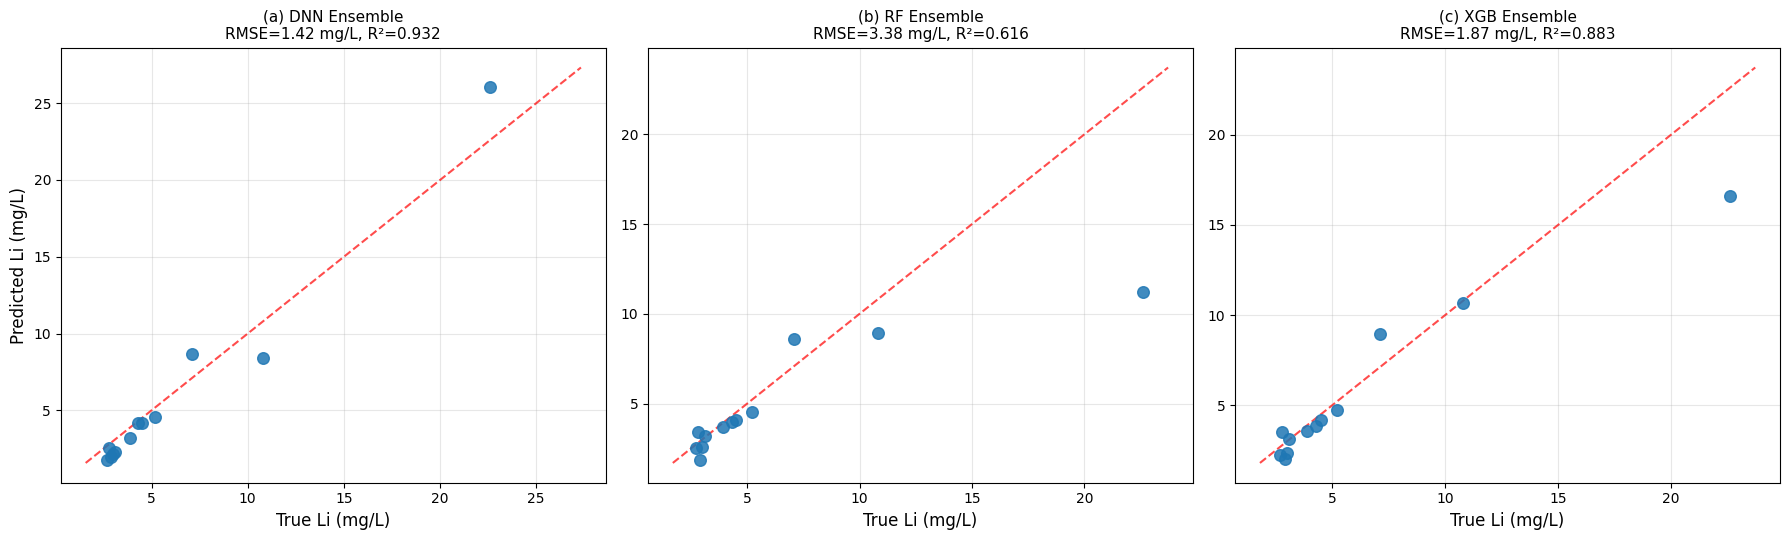

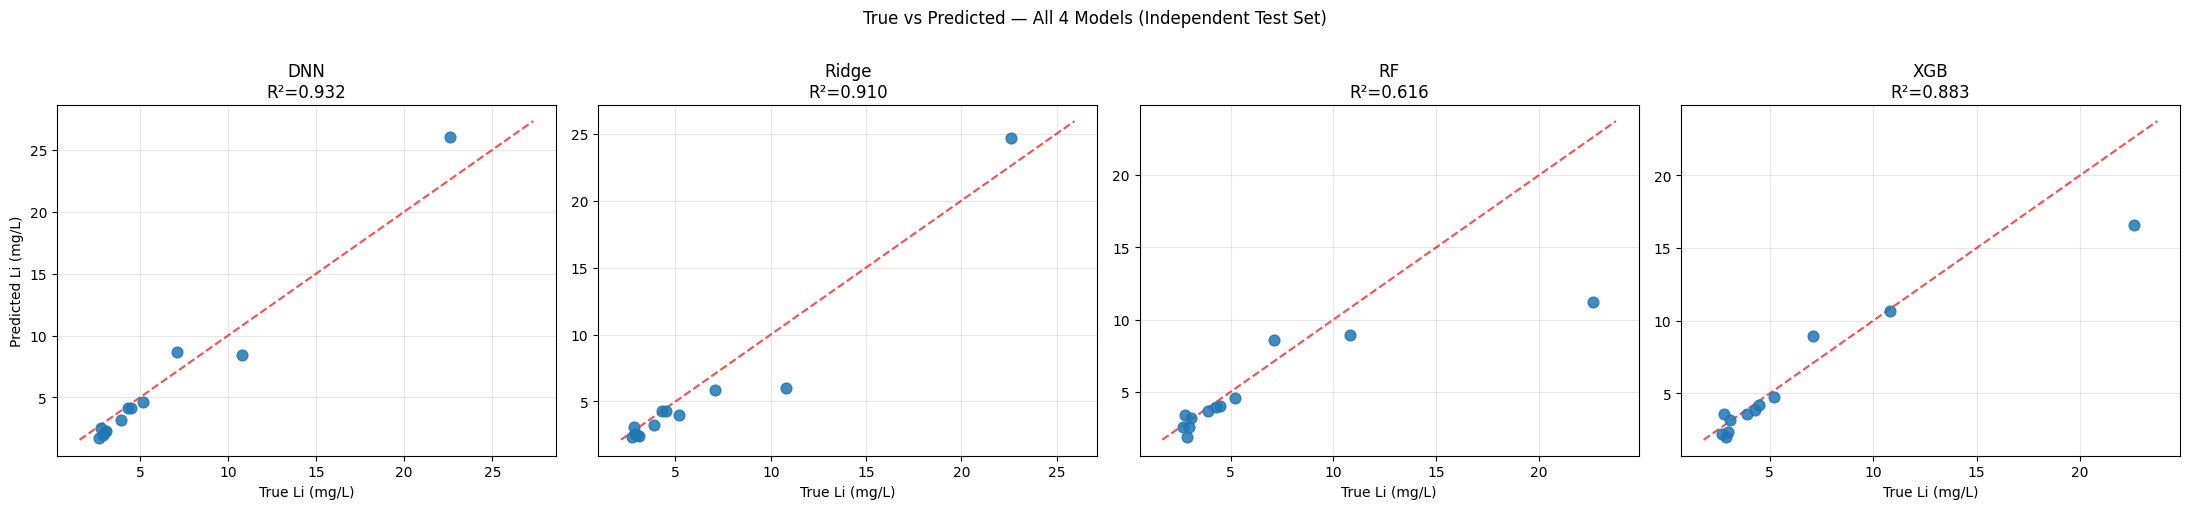

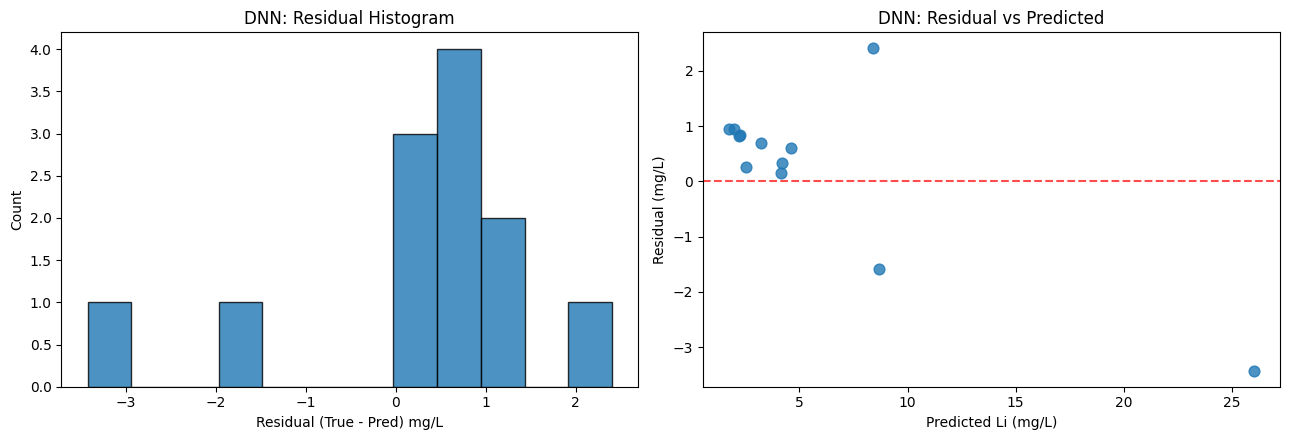

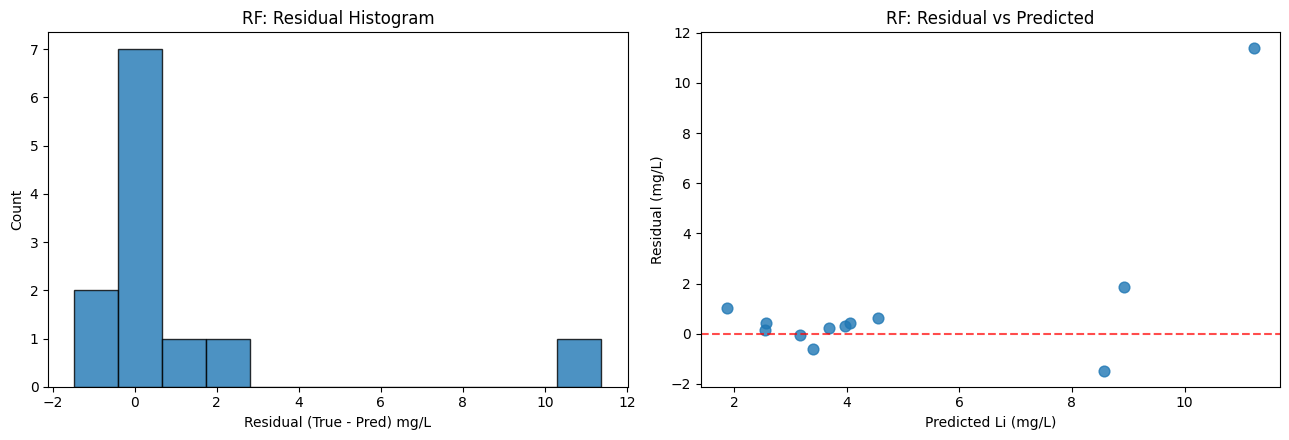

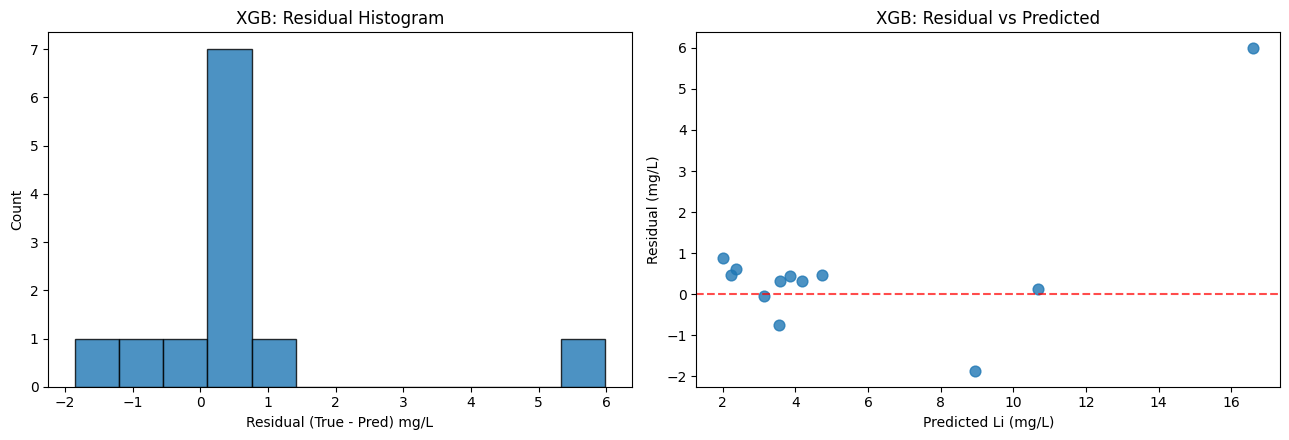

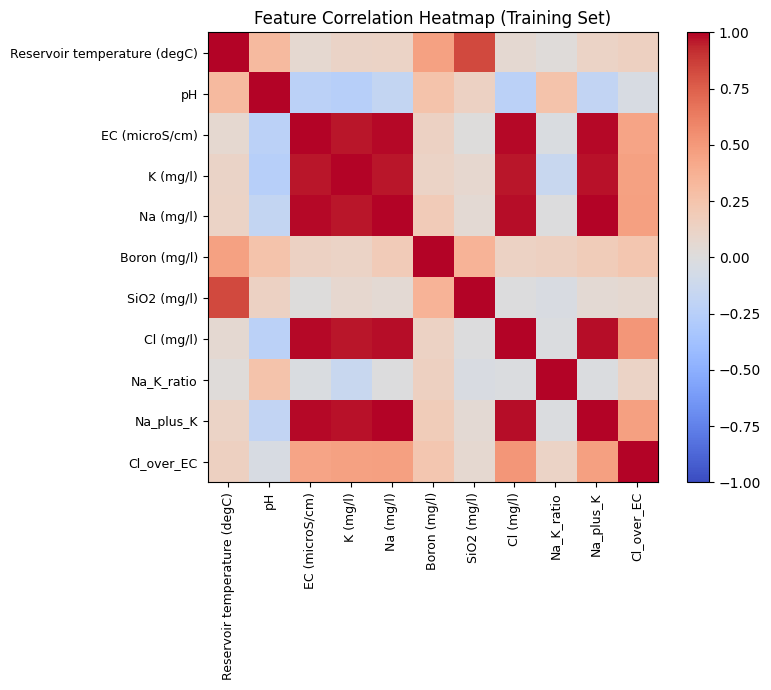

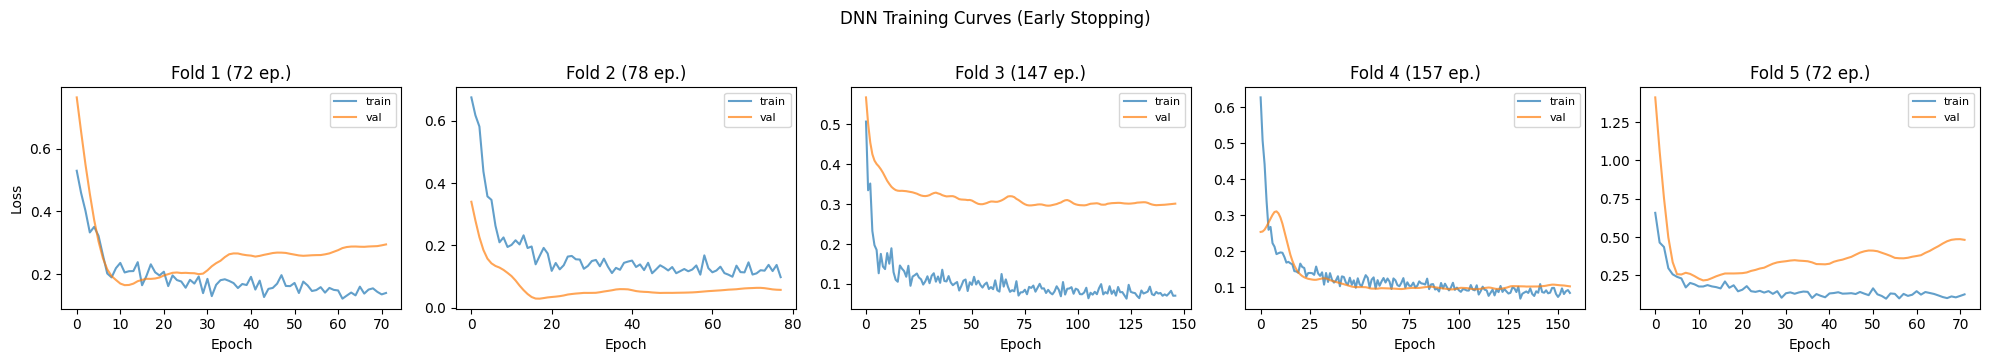

All figures saved.


In [7]:
# --- Parity plots (DNN, RF, XGB) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for i, m in enumerate(['DNN', 'RF', 'XGB']):
    y_pred = test_results[m]['preds']
    r = test_results[m]
    ax = axes[i]
    ax.scatter(y_test_raw, y_pred, alpha=0.85, s=70, zorder=3)
    lo = min(y_test_raw.min(), y_pred.min()) * 0.9
    hi = max(y_test_raw.max(), y_pred.max()) * 1.05
    ax.plot([lo,hi],[lo,hi],'r--', alpha=0.7, zorder=2)
    ax.set_xlabel('True Li (mg/L)', fontsize=12)
    if i == 0: ax.set_ylabel('Predicted Li (mg/L)', fontsize=12)
    ax.set_title(f'({chr(97+i)}) {m} Ensemble\nRMSE={r["rmse"]:.2f} mg/L, R²={r["r2"]:.3f}', fontsize=11)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig9_parity_plots.png'), dpi=300, bbox_inches='tight')
plt.show()

# --- Parity plot with Ridge (supplementary or for comparison) ---
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for i, m in enumerate(['DNN', 'Ridge', 'RF', 'XGB']):
    y_pred = test_results[m]['preds']
    r = test_results[m]
    ax = axes[i]
    ax.scatter(y_test_raw, y_pred, alpha=0.85, s=60, zorder=3)
    lo = min(y_test_raw.min(), y_pred.min()) * 0.9
    hi = max(y_test_raw.max(), y_pred.max()) * 1.05
    ax.plot([lo,hi],[lo,hi],'r--', alpha=0.7)
    ax.set_xlabel('True Li (mg/L)'); ax.set_title(f'{m}\nR²={r["r2"]:.3f}')
    if i == 0: ax.set_ylabel('Predicted Li (mg/L)')
    ax.grid(True, alpha=0.3)
plt.suptitle('True vs Predicted — All 4 Models (Independent Test Set)', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'parity_4models.png'), dpi=300, bbox_inches='tight')
plt.show()

# --- Residual plots ---
for m in ['DNN', 'RF', 'XGB']:
    y_pred = test_results[m]['preds']
    resid = y_test_raw - y_pred
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.hist(resid, bins=12, alpha=0.8, edgecolor='black')
    ax1.set_xlabel('Residual (True - Pred) mg/L'); ax1.set_ylabel('Count')
    ax1.set_title(f'{m}: Residual Histogram')
    ax2.scatter(y_pred, resid, alpha=0.8, s=60)
    ax2.axhline(0, ls='--', c='r', alpha=0.7)
    ax2.set_xlabel('Predicted Li (mg/L)'); ax2.set_ylabel('Residual (mg/L)')
    ax2.set_title(f'{m}: Residual vs Predicted')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, f'Fig_residuals_{m.lower()}.png'), dpi=300, bbox_inches='tight')
    plt.show()

# --- Correlation heatmap ---
corr = np.corrcoef(X_train_raw.values.T)
plt.figure(figsize=(9,7))
im = plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(feature_names_ext)), feature_names_ext, rotation=90, fontsize=9)
plt.yticks(range(len(feature_names_ext)), feature_names_ext, fontsize=9)
plt.title('Feature Correlation Heatmap (Training Set)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig7_corr_heatmap.png'), dpi=300); plt.show()

# --- SHAP beeswarm ---
xgb_full = XGBRegressor(**XGB_PARAMS)
xgb_full.fit(X_train_raw.values, np.log1p(y_train_raw))
explainer = shap.TreeExplainer(xgb_full)
shap_vals = explainer.shap_values(X_train_raw.values)
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_vals, X_train_raw.values, feature_names=feature_names_ext, show=False)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig12_shap_beeswarm.png'), dpi=300, bbox_inches='tight'); plt.close()

# --- DNN training curves ---
fig, axes = plt.subplots(1, N_SPLITS, figsize=(4*N_SPLITS, 3.5))
for i, h in enumerate(histories):
    ax = axes[i]
    ax.plot(h['loss'], label='train', alpha=0.7)
    ax.plot(h['val_loss'], label='val', alpha=0.7)
    ax.set_title(f'Fold {i+1} ({len(h["loss"])} ep.)')
    ax.set_xlabel('Epoch'); ax.legend(fontsize=8)
    if i == 0: ax.set_ylabel('Loss')
plt.suptitle('DNN Training Curves (Early Stopping)', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'FigA_dnn_training_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

print("All figures saved.")

# PART C: Reviewer Deneyleri

## C1: GroupKFold Diagnostics (A5)

In [8]:
print("="*60)
print("GROUPKFOLD DIAGNOSTICS")
print("="*60)
unique_groups = np.unique(groups)
print(f"Unique groups: {len(unique_groups)}")
grp_counts = pd.Series(groups).value_counts().sort_values(ascending=False)
print(f"\nGroup sizes:\n{grp_counts.to_string()}")

print(f"\nFold assignments:")
for fold_i, (tr_i, va_i) in enumerate(folds_list, 1):
    vg = sorted(np.unique(groups[va_i]))
    print(f"  Fold {fold_i}: val n={len(va_i)}, groups={vg}")

print(f"\nTest set: n={len(y_test_raw)}")
print(f"  Locations: {list(test_n['Location'].values)}")
print(f"  Li range: {y_test_raw.min():.2f} - {y_test_raw.max():.2f} mg/L")

GROUPKFOLD DIAGNOSTICS
Unique groups: 26

Group sizes:
Kızıldere     10
Germencik     10
Tekkehamam     7
Aydın          6
Alaşehir       5
İzmir          5
Salavatlı      4
Yenicekent     3
Afyon          3
Ağrı           3
Salihli        2
Konya          2
Ortaklar       1
Sarayköy       1
Sakarya        1
Tuzla          1
Gönen          1
Bigadiç        1
Naşa           1
Çitli          1
Eynal          1
Kırşehir       1
Niğde          1
Rize           1
Samsun         1
Erzurum        1

Fold assignments:
  Fold 1: val n=15, groups=['Afyon', 'Germencik', 'Ortaklar', 'Rize']
  Fold 2: val n=15, groups=['Ağrı', 'Bigadiç', 'Gönen', 'Kızıldere']
  Fold 3: val n=15, groups=['Eynal', 'Konya', 'Kırşehir', 'Tekkehamam', 'Yenicekent', 'Çitli']
  Fold 4: val n=15, groups=['Aydın', 'Erzurum', 'Niğde', 'Salavatlı', 'Salihli', 'Samsun']
  Fold 5: val n=14, groups=['Alaşehir', 'Naşa', 'Sakarya', 'Sarayköy', 'Tuzla', 'İzmir']

Test set: n=12
  Locations: ['Kızıldere', 'Kızıldere', 'Kızıldere', '

## C2: DNN Effective Complexity (A3)

In [9]:
n_feat = X_train_raw.shape[1]
p1 = (n_feat+1)*64; p2 = (64+1)*64; p3 = (64+1)*32; p4 = (32+1)*1
total_params = p1+p2+p3+p4
n_train_fold = int(len(y_train_raw) * (N_SPLITS-1) / N_SPLITS)

print("="*60)
print("DNN EFFECTIVE COMPLEXITY")
print("="*60)
print(f"Architecture: [{n_feat}] -> 64 -> 64 -> 32 -> 1")
print(f"Nominal parameters: {total_params:,}")
print(f"Regularization: L2={L2}, Dropout={DROPOUT}, EarlyStop patience={PATIENCE}")
print(f"Early stopping epochs: {early_stop_epochs}")
print(f"  Mean: {np.mean(early_stop_epochs):.0f}, Range: {min(early_stop_epochs)}-{max(early_stop_epochs)} / {EPOCHS} max")
print(f"Samples per fold: ~{n_train_fold}")
print(f"Samples/params ratio: {n_train_fold/total_params:.4f}")

DNN EFFECTIVE COMPLEXITY
Architecture: [11] -> 64 -> 64 -> 32 -> 1
Nominal parameters: 7,041
Regularization: L2=0.0001, Dropout=0.12, EarlyStop patience=60
Early stopping epochs: [72, 78, 147, 157, 72]
  Mean: 105, Range: 72-157 / 800 max
Samples per fold: ~59
Samples/params ratio: 0.0084


## C3: DNN vs Ridge Bootstrap + LOO Sensitivity

In [10]:
y_pred_dnn = test_results['DNN']['preds']
y_pred_ridge = test_results['Ridge']['preds']

abs_err_dnn = np.abs(y_test_raw - y_pred_dnn)
abs_err_ridge = np.abs(y_test_raw - y_pred_ridge)
obs_diff = abs_err_ridge.mean() - abs_err_dnn.mean()

# Bootstrap
np.random.seed(SEED)
boot_diffs = np.array([
    abs_err_ridge[np.random.choice(len(y_test_raw), len(y_test_raw), replace=True)].mean() -
    abs_err_dnn[np.random.choice(len(y_test_raw), len(y_test_raw), replace=True)].mean()
    for _ in range(10000)])
p_boot = np.mean(boot_diffs <= 0)
ci_lo, ci_hi = np.percentile(boot_diffs, [2.5, 97.5])

# Permutation
combined = np.stack([abs_err_dnn, abs_err_ridge])
perm_diffs = []
for _ in range(10000):
    swaps = np.random.randint(0, 2, size=len(y_test_raw))
    pd_ = combined[1-swaps, range(len(y_test_raw))].mean() - combined[swaps, range(len(y_test_raw))].mean()
    perm_diffs.append(pd_)
p_perm = np.mean(np.array(perm_diffs) >= obs_diff)

print("="*60)
print("PAIRED BOOTSTRAP: DNN vs Ridge")
print("="*60)
print(f"Observed MAE diff (Ridge-DNN): {obs_diff:.4f} mg/L")
print(f"Bootstrap 95% CI: [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"Bootstrap p-value: {p_boot:.4f}")
print(f"Permutation p-value: {p_perm:.4f}")
sig = "SIGNIFICANT" if (p_boot < 0.05 and ci_lo > 0) else "NOT significant"
print(f"=> DNN advantage is {sig} at alpha=0.05")

# LOO
print("\n" + "="*60)
print("LEAVE-ONE-OUT SENSITIVITY")
print("="*60)
loo_rows = []
sid_col = 'Sample ID' if 'Sample ID' in test_n.columns else None
for i in range(len(y_test_raw)):
    mask = np.ones(len(y_test_raw), dtype=bool); mask[i] = False
    r2d = r2_score(y_test_raw[mask], y_pred_dnn[mask])
    r2r = r2_score(y_test_raw[mask], y_pred_ridge[mask])
    sid = test_n.iloc[i][sid_col] if sid_col else f"s{i}"
    loo_rows.append([sid, y_test_raw[i], r2d, r2r, r2d-r2r])
loo_df = pd.DataFrame(loo_rows, columns=['Sample','Li_true','DNN_R2','Ridge_R2','Diff'])
print(loo_df.to_string(index=False, float_format='%.4f'))
loo_df.to_csv(os.path.join(OUT, 'loo_sensitivity.csv'), index=False)

tuzla_i = np.argmax(y_test_raw)
print(f"\nHighest-Li: {loo_df.iloc[tuzla_i]['Sample']} (Li={y_test_raw[tuzla_i]:.1f})")
print(f"  Without it: DNN R²={loo_df.iloc[tuzla_i]['DNN_R2']:.4f}, Ridge R²={loo_df.iloc[tuzla_i]['Ridge_R2']:.4f}")

PAIRED BOOTSTRAP: DNN vs Ridge
Observed MAE diff (Ridge-DNN): -0.0504 mg/L
Bootstrap 95% CI: [-0.8875, 0.8842]
Bootstrap p-value: 0.5676
Permutation p-value: 0.5614
=> DNN advantage is NOT significant at alpha=0.05

LEAVE-ONE-OUT SENSITIVITY
    Sample  Li_true  DNN_R2  Ridge_R2    Diff
    KD-23B   4.3000  0.9317    0.9091  0.0226
     KD-2A   4.5000  0.9321    0.9094  0.0227
    KD-38A   2.8000  0.9302    0.9072  0.0230
     KD-14   3.9000  0.9326    0.9099  0.0227
        W2   3.0000  0.9322    0.9080  0.0242
        S1   3.1000  0.9324    0.9087  0.0238
        S3   2.7000  0.9324    0.9070  0.0254
      AS-4   5.2000  0.9331    0.9141  0.0191
      OB-1   7.1000  0.9391    0.9139  0.0252
      RE-2  10.8000  0.9446    0.9732 -0.0286
Kurşunlu-3   2.9000  0.9327    0.9075  0.0252
        T1  22.6000  0.7918    0.5377  0.2541

Highest-Li: T1 (Li=22.6)
  Without it: DNN R²=0.7918, Ridge R²=0.5377


## C4: Fold 1 Diagnostics

In [11]:
tr_idx, val_idx = folds_list[0]
y_va = y_train_raw[val_idx]

print("="*60)
print("FOLD 1 DIAGNOSTICS")
print("="*60)
print(f"Val groups: {sorted(np.unique(groups[val_idx]))}")
val_info = train_n.iloc[val_idx][['Sample ID','Location',target]].sort_values(target, ascending=False)
print(f"\nVal samples (sorted by Li):")
print(val_info.to_string(index=False))
print(f"\nTrain Li: max={y_train_raw[tr_idx].max():.1f}, mean={y_train_raw[tr_idx].mean():.2f}")
print(f"Val   Li: max={y_va.max():.1f}, mean={y_va.mean():.2f}")

# Per-model predictions on fold 1
X_tr_f = X_train_raw.iloc[tr_idx]; X_va_f = X_train_raw.iloc[val_idx]; y_tr_f = y_train_raw[tr_idx]
xsc = StandardScaler(); X_tr_s = xsc.fit_transform(X_tr_f.values); X_va_s = xsc.transform(X_va_f.values)
y_log = np.log1p(y_tr_f); mu = y_log.mean(); sig = y_log.std()+1e-8

dnn_f = build_dnn(X_tr_s.shape[1])
dnn_f.fit(X_tr_s, (y_log-mu)/sig, validation_data=(X_va_s, (np.log1p(y_va)-mu)/sig),
          epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
          callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=0)])
p_dnn = inv_dnn(dnn_f.predict(X_va_s, verbose=0).ravel(), mu, sig)

rf_f = RandomForestRegressor(**RF_PARAMS); rf_f.fit(X_tr_f.values, np.log1p(y_tr_f))
p_rf = np.expm1(rf_f.predict(X_va_f.values))

xgb_f = XGBRegressor(**XGB_PARAMS); xgb_f.fit(X_tr_f.values, np.log1p(y_tr_f))
p_xgb = np.expm1(xgb_f.predict(X_va_f.values))

diag = pd.DataFrame({'Sample': train_n.iloc[val_idx]['Sample ID'].values,
    'Location': train_n.iloc[val_idx]['Location'].values,
    'Li_true': y_va, 'DNN': p_dnn, 'RF': p_rf, 'XGB': p_xgb})
diag = diag.sort_values('Li_true', ascending=False)
for m in ['DNN','RF','XGB']: diag[f'{m}_err'] = diag['Li_true'] - diag[m]
print("\nPer-sample predictions:")
print(diag.to_string(index=False, float_format='%.2f'))
diag.to_csv(os.path.join(OUT, 'fold1_diagnostics.csv'), index=False)

# R² with/without max-Li sample
mx = np.argmax(y_va); msk = np.ones(len(y_va), dtype=bool); msk[mx] = False
print(f"\nHighest-Li in Fold 1: {y_va[mx]:.1f} mg/L ({train_n.iloc[val_idx[mx]]['Sample ID']})")
print(f"R² WITH:    DNN={r2_score(y_va, p_dnn):.3f}, RF={r2_score(y_va, p_rf):.3f}, XGB={r2_score(y_va, p_xgb):.3f}")
if msk.sum() > 1:
    print(f"R² WITHOUT: DNN={r2_score(y_va[msk], p_dnn[msk]):.3f}, RF={r2_score(y_va[msk], p_rf[msk]):.3f}, XGB={r2_score(y_va[msk], p_xgb[msk]):.3f}")

FOLD 1 DIAGNOSTICS
Val groups: ['Afyon', 'Germencik', 'Ortaklar', 'Rize']

Val samples (sorted by Li):
 Sample ID  Location  Li (mg/l)
      OB-6 Germencik       11.6
     AG-22 Germencik       11.4
     OB-14 Germencik       10.6
      RE-1 Germencik       10.1
     OB-10 Germencik        9.4
     OB-17 Germencik        7.8
      HB-7 Germencik        7.5
      OB-2 Germencik        7.4
      HB-5 Germencik        6.3
       HB8 Germencik        6.3
Ilıcaköy-2      Rize        5.7
      AF20     Afyon        2.3
      AF-6     Afyon        2.2
       OZ2     Afyon        2.0
 Magnez K.  Ortaklar        1.0

Train Li: max=21.6, mean=3.74
Val   Li: max=11.6, mean=6.77

Per-sample predictions:
    Sample  Location  Li_true  DNN   RF  XGB  DNN_err  RF_err  XGB_err
      OB-6 Germencik    11.60 6.25 6.58 6.05     5.35    5.02     5.55
     AG-22 Germencik    11.40 7.98 6.50 5.43     3.42    4.90     5.97
     OB-14 Germencik    10.60 6.14 6.01 5.88     4.46    4.59     4.72
      RE-1 Germ

## C5: Mg²⁺ Ablation (B13)

In [12]:
print("="*60)
print("Mg²⁺ ABLATION")
print("="*60)
mg_rows = []
for label, inc, mode in [('No Mg',False,None), ('Mg raw',True,'raw'), ('Mg log',True,'log'), ('Mg binary',True,'binary')]:
    Xtr = build_features(train_n, include_mg=inc, mg_mode=mode)
    Xte = build_features(test_n, include_mg=inc, mg_mode=mode)
    for mname, Model, params in [('RF', RandomForestRegressor, RF_PARAMS), ('XGB', XGBRegressor, XGB_PARAMS)]:
        fold_preds = []; fold_r2s = []
        for tr_i, va_i in folds_list:
            m = Model(**params); m.fit(Xtr.iloc[tr_i].values, np.log1p(y_train_raw[tr_i]))
            fold_preds.append(np.expm1(m.predict(Xte.values)))
            fold_r2s.append(r2_score(y_train_raw[va_i], np.expm1(m.predict(Xtr.iloc[va_i].values))))
        y_ens = np.median(np.vstack(fold_preds), axis=0)
        rmse, mae, r2, _ = full_scores(y_test_raw, y_ens)
        mg_rows.append([label, mname, Xtr.shape[1], rmse, mae, r2, np.mean(fold_r2s)])
mg_df = pd.DataFrame(mg_rows, columns=['Mg_config','Model','n_feat','RMSE','MAE','R2','CV_R2_mean'])
print(mg_df.round(4).to_string(index=False))
mg_df.to_csv(os.path.join(OUT, 'mg_ablation.csv'), index=False)

Mg²⁺ ABLATION
Mg_config Model  n_feat   RMSE    MAE     R2  CV_R2_mean
    No Mg    RF      11 3.3837 1.5526 0.6163      0.3101
    No Mg   XGB      11 1.8691 1.0275 0.8829      0.2534
   Mg raw    RF      12 3.4533 1.5712 0.6004      0.2530
   Mg raw   XGB      12 2.1016 1.1098 0.8520      0.1711
   Mg log    RF      12 3.4533 1.5715 0.6004      0.2527
   Mg log   XGB      12 2.1016 1.1098 0.8520      0.1711
Mg binary    RF      12 3.4188 1.5498 0.6083      0.2678
Mg binary   XGB      12 2.0856 1.1117 0.8542      0.2578


## C6: Feature Engineering Ablation (B16)

In [13]:
print("="*60)
print("FEATURE ENGINEERING ABLATION")
print("="*60)
fa_rows = []
for label, fmode in [('raw_only (8)', 'raw_only'), ('engineered_only (8)', 'engineered_only'), ('combined (11)', 'combined')]:
    Xtr = build_features(train_n, feature_mode=fmode)
    Xte = build_features(test_n, feature_mode=fmode)
    print(f"\n{label}: {list(Xtr.columns)}")
    for mname, Model, params in [('RF', RandomForestRegressor, RF_PARAMS), ('XGB', XGBRegressor, XGB_PARAMS),
                                  ('DNN', None, None)]:
        fold_preds = []; fold_r2s = []
        for tr_i, va_i in folds_list:
            if mname == 'DNN':
                sc = StandardScaler()
                Xtr_s = sc.fit_transform(Xtr.iloc[tr_i].values); Xva_s = sc.transform(Xtr.iloc[va_i].values)
                Xte_s = sc.transform(Xte.values)
                yl = np.log1p(y_train_raw[tr_i]); mu_ = yl.mean(); si_ = yl.std()+1e-8
                d = build_dnn(Xtr_s.shape[1])
                d.fit(Xtr_s, (yl-mu_)/si_, validation_data=(Xva_s, (np.log1p(y_train_raw[va_i])-mu_)/si_),
                      epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
                      callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=0)])
                fold_preds.append(inv_dnn(d.predict(Xte_s, verbose=0).ravel(), mu_, si_))
                fold_r2s.append(r2_score(y_train_raw[va_i], inv_dnn(d.predict(Xva_s, verbose=0).ravel(), mu_, si_)))
            else:
                m = Model(**params); m.fit(Xtr.iloc[tr_i].values, np.log1p(y_train_raw[tr_i]))
                fold_preds.append(np.expm1(m.predict(Xte.values)))
                fold_r2s.append(r2_score(y_train_raw[va_i], np.expm1(m.predict(Xtr.iloc[va_i].values))))
        y_ens = np.median(np.vstack(fold_preds), axis=0)
        rmse, mae, r2, _ = full_scores(y_test_raw, y_ens)
        fa_rows.append([label, mname, Xtr.shape[1], rmse, mae, r2, np.mean(fold_r2s)])
fa_df = pd.DataFrame(fa_rows, columns=['Config','Model','n_feat','RMSE','MAE','R2','CV_R2_mean'])
print("\n" + fa_df.round(4).to_string(index=False))
fa_df.to_csv(os.path.join(OUT, 'feature_ablation.csv'), index=False)

FEATURE ENGINEERING ABLATION

raw_only (8): ['Reservoir temperature (degC)', 'pH', 'EC (microS/cm)', 'K (mg/l)', 'Na (mg/l)', 'Boron (mg/l)', 'SiO2 (mg/l)', 'Cl (mg/l)']

engineered_only (8): ['Reservoir temperature (degC)', 'pH', 'EC (microS/cm)', 'Na_K_ratio', 'Na_plus_K', 'Cl_over_EC', 'Boron (mg/l)', 'SiO2 (mg/l)']

combined (11): ['Reservoir temperature (degC)', 'pH', 'EC (microS/cm)', 'K (mg/l)', 'Na (mg/l)', 'Boron (mg/l)', 'SiO2 (mg/l)', 'Cl (mg/l)', 'Na_K_ratio', 'Na_plus_K', 'Cl_over_EC']

             Config Model  n_feat   RMSE    MAE      R2  CV_R2_mean
       raw_only (8)    RF       8 3.5623 1.6466  0.5747      0.1256
       raw_only (8)   XGB       8 1.8868 1.0603  0.8807      0.1918
       raw_only (8)   DNN       8 4.9262 2.0722  0.1867      0.3599
engineered_only (8)    RF       8 3.5772 1.6584  0.5712      0.2569
engineered_only (8)   XGB       8 2.0161 1.0907  0.8638      0.3084
engineered_only (8)   DNN       8 3.9421 1.8490  0.4792      0.5701
      combined (11)

## C7: SiO₂/T Ablation

In [14]:
print("="*60)
print("SiO2/T ABLATION")
print("="*60)
sio2_rows = []
for label, add_sio2t in [('without SiO2/T', False), ('with SiO2/T', True)]:
    Xtr = build_features(train_n); Xte = build_features(test_n)
    if add_sio2t:
        T_tr = train_n[feat_names[0]].astype(float).values; S_tr = train_n[feat_names[6]].astype(float).values
        Xtr['SiO2_T'] = S_tr / (T_tr + 1e-6)
        T_te = test_n[feat_names[0]].astype(float).values; S_te = test_n[feat_names[6]].astype(float).values
        Xte['SiO2_T'] = S_te / (T_te + 1e-6)
    for mname, Model, params in [('RF', RandomForestRegressor, RF_PARAMS), ('XGB', XGBRegressor, XGB_PARAMS)]:
        fold_preds = []; fold_r2s = []
        for tr_i, va_i in folds_list:
            m = Model(**params); m.fit(Xtr.iloc[tr_i].values, np.log1p(y_train_raw[tr_i]))
            fold_preds.append(np.expm1(m.predict(Xte.values)))
            fold_r2s.append(r2_score(y_train_raw[va_i], np.expm1(m.predict(Xtr.iloc[va_i].values))))
        y_ens = np.median(np.vstack(fold_preds), axis=0)
        rmse, mae, r2, _ = full_scores(y_test_raw, y_ens)
        sio2_rows.append([label, mname, rmse, r2, np.mean(fold_r2s)])
s_df = pd.DataFrame(sio2_rows, columns=['Config','Model','RMSE','R2','CV_R2_mean'])
print(s_df.round(4).to_string(index=False))
s_df.to_csv(os.path.join(OUT, 'sio2t_ablation.csv'), index=False)

SiO2/T ABLATION
        Config Model   RMSE     R2  CV_R2_mean
without SiO2/T    RF 3.3837 0.6163      0.3101
without SiO2/T   XGB 1.8691 0.8829      0.2534
   with SiO2/T    RF 3.4569 0.5995      0.2674
   with SiO2/T   XGB 2.2109 0.8362      0.2207


## C8: Conformal Coverage Binomial CI

In [15]:
print("="*60)
print("CONFORMAL COVERAGE: BINOMIAL CI (n=12)")
print("="*60)
n = 12
for k in [10, 11, 12]:
    ci_lo = stats.beta.ppf(0.025, k, n-k+1) if k > 0 else 0.0
    ci_hi = stats.beta.ppf(0.975, k+1, n-k) if k < n else 1.0
    print(f"  k={k}/{n} ({k/n*100:.1f}%): 95% Clopper-Pearson CI = [{ci_lo*100:.1f}%, {ci_hi*100:.1f}%]")
k_obs = 11
ci_l = stats.beta.ppf(0.025, k_obs, n-k_obs+1)
ci_h = stats.beta.ppf(0.975, k_obs+1, n-k_obs)
print(f"\nFor paper: 91.7% observed coverage, 95% CI [{ci_l*100:.0f}%, {ci_h*100:.0f}%]")

CONFORMAL COVERAGE: BINOMIAL CI (n=12)
  k=10/12 (83.3%): 95% Clopper-Pearson CI = [51.6%, 97.9%]
  k=11/12 (91.7%): 95% Clopper-Pearson CI = [61.5%, 99.8%]
  k=12/12 (100.0%): 95% Clopper-Pearson CI = [73.5%, 100.0%]

For paper: 91.7% observed coverage, 95% CI [62%, 100%]


## C9: Mg²⁺ Completeness Report

In [16]:
mg_tr = train_n[mg_col].astype(float)
mg_te = test_n[mg_col].astype(float)
print(f"Train: {mg_tr.notna().sum()}/{len(mg_tr)} have Mg ({mg_tr.isna().sum()} missing)")
print(f"Test:  {mg_te.notna().sum()}/{len(mg_te)} have Mg ({mg_te.isna().sum()} missing)")
print(f"Train Mg < 1.0: {(mg_tr < 1.0).sum()}/{len(mg_tr)} ({(mg_tr < 1.0).mean()*100:.0f}%)")
print(f"Train Mg stats: min={mg_tr.min():.2f}, max={mg_tr.max():.2f}, median={mg_tr.median():.2f}")

Train: 74/74 have Mg (0 missing)
Test:  12/12 have Mg (0 missing)
Train Mg < 1.0: 20/74 (27%)
Train Mg stats: min=0.00, max=175.00, median=10.50


# PART D: Makaleye Aktarılacak Değerler
Bu hücrenin çıktısını doğrudan kullan.

In [17]:
print("="*70)
print("MAKALEYE AKTARILACAK DEĞERLER")
print("="*70)

d = test_results['DNN']; ri = test_results['Ridge']
rf = test_results['RF']; xg = test_results['XGB']

print(f"""
ABSTRACT:
  "...three regressors (DNN, Random Forest, XGBoost) were evaluated on
   86 springs and wells compiled from published studies and technical
   reports across Türkiye under a leakage-free protocol with
   split-conformal uncertainty. On the independent test set (n=12,
   Western Anatolia and Marmara), the compact DNN yielded RMSE ≈
   {d['rmse']:.2f} mg/L, MAE ≈ {d['mae']:.2f} mg/L, R² ≈ {d['r2']:.2f}..."

SECTION 4.2 (Test-Set Performance):
  DNN:   RMSE={d['rmse']:.3f}, MAE={d['mae']:.3f}, R²={d['r2']:.3f}, MAPE={d['mape']:.1f}%
  Ridge: RMSE={ri['rmse']:.3f}, MAE={ri['mae']:.3f}, R²={ri['r2']:.3f}, MAPE={ri['mape']:.1f}%
  RF:    RMSE={rf['rmse']:.3f}, MAE={rf['mae']:.3f}, R²={rf['r2']:.3f}, MAPE={rf['mape']:.1f}%
  XGB:   RMSE={xg['rmse']:.3f}, MAE={xg['mae']:.3f}, R²={xg['r2']:.3f}, MAPE={xg['mape']:.1f}%

CONFORMAL PREDICTION:
  DNN:   coverage={d['cov']*100:.1f}%, width={d['width']:.3f} mg/L
  Ridge: coverage={ri['cov']*100:.1f}%, width={ri['width']:.3f} mg/L
  RF:    coverage={rf['cov']*100:.1f}%, width={rf['width']:.3f} mg/L
  XGB:   coverage={xg['cov']*100:.1f}%, width={xg['width']:.3f} mg/L

BOOTSTRAP (DNN vs Ridge):
  MAE diff: {obs_diff:.4f}, 95% CI: [{ci_lo:.4f}, {ci_hi:.4f}], p={p_boot:.4f}
  {"SIGNIFICANT" if p_boot < 0.05 else "NOT significant"}

DNN COMPLEXITY:
  Params: {total_params:,}, Early stop: mean {np.mean(early_stop_epochs):.0f} epochs
  ({min(early_stop_epochs)}-{max(early_stop_epochs)} range, max {EPOCHS})

CONCLUSION:
  "...the compact DNN achieved the lowest error (RMSE ≈ {d['rmse']:.2f} mg/L,
   R² ≈ {d['r2']:.2f}), though a paired bootstrap test showed that the
   advantage over Ridge (R² = {ri['r2']:.2f}) is not statistically significant
   on this 12-sample test set (p = {p_boot:.2f})..."
""")

MAKALEYE AKTARILACAK DEĞERLER

ABSTRACT:
  "...three regressors (DNN, Random Forest, XGBoost) were evaluated on
   86 springs and wells compiled from published studies and technical
   reports across Türkiye under a leakage-free protocol with
   split-conformal uncertainty. On the independent test set (n=12,
   Western Anatolia and Marmara), the compact DNN yielded RMSE ≈
   1.42 mg/L, MAE ≈ 1.08 mg/L, R² ≈ 0.93..."

SECTION 4.2 (Test-Set Performance):
  DNN:   RMSE=1.422, MAE=1.084, R²=0.932, MAPE=19.3%
  Ridge: RMSE=1.639, MAE=1.034, R²=0.910, MAPE=15.8%
  RF:    RMSE=3.384, MAE=1.553, R²=0.616, MAPE=16.9%
  XGB:   RMSE=1.869, MAE=1.028, R²=0.883, MAPE=15.5%

CONFORMAL PREDICTION:
  DNN:   coverage=91.7%, width=6.013 mg/L
  Ridge: coverage=91.7%, width=5.702 mg/L
  RF:    coverage=91.7%, width=4.397 mg/L
  XGB:   coverage=91.7%, width=5.911 mg/L

BOOTSTRAP (DNN vs Ridge):
  MAE diff: -0.0504, 95% CI: [0.7354, 1.0000], p=0.5676
  NOT significant

DNN COMPLEXITY:
  Params: 7,041, Early

In [18]:
# Save all predictions
pred_data = {'y_true': y_test_raw}
for m in ['DNN','Ridge','RF','XGB']:
    pred_data[f'pred_{m}'] = test_results[m]['preds']
    pred_data[f'cp_lo_{m}'] = test_results[m]['preds'] - q_hat[m]
    pred_data[f'cp_hi_{m}'] = test_results[m]['preds'] + q_hat[m]
pd.DataFrame(pred_data).to_csv(os.path.join(OUT, 'predictions_all.csv'), index=False)

shutil.make_archive(OUT, 'zip', OUT)
from google.colab import files as cf
cf.download(f'{OUT}.zip')
print(f"\nDone. Files:")
for f in sorted(os.listdir(OUT)): print(f"  {f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done. Files:
  Fig12_shap_beeswarm.png
  Fig7_corr_heatmap.png
  Fig9_parity_plots.png
  FigA_dnn_training_curves.png
  Fig_residuals_dnn.png
  Fig_residuals_rf.png
  Fig_residuals_xgb.png
  TABLE3_test_metrics.csv
  TABLE4_cv_perfold.csv
  TABLE5_cv_summary.csv
  cv_metrics_all.csv
  feature_ablation.csv
  fold1_diagnostics.csv
  loo_sensitivity.csv
  mg_ablation.csv
  parity_4models.png
  predictions_all.csv
  sio2t_ablation.csv
